# Individual Assignment 3: Community Detection
### Zachary's Karate Club Network Analysis

## 1. Import Libraries

In [1]:
import os
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from networkx.algorithms.community.quality import modularity

# Set seed for reproducibility
random.seed(42)
np.random.seed(42)

## 2. Load Dataset & Ground Truth

In [2]:
# Load edge list from ucidata-zachary
edges = []
with open("ucidata-zachary/out.ucidata-zachary", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("%"):
            continue
        u, v = map(int, line.split()[:2])
        edges.append((u, v))

G = nx.Graph()
G.add_edges_from(edges)

# Load Zachary's ground truth factions
zkc = nx.karate_club_graph()
ground_truth = {n + 1: zkc.nodes[n]["club"] for n in zkc.nodes()}

print(f"Total Nodes: {G.number_of_nodes()}")
print(f"Total Edges: {G.number_of_edges()}")

Total Nodes: 34
Total Edges: 78


## 3. Basic Network Statistics

In [3]:
stats = {
    "Number of Nodes": G.number_of_nodes(),
    "Number of Edges": G.number_of_edges(),
    "Density": round(nx.density(G), 4),
    "Average Degree": round(2 * G.number_of_edges() / G.number_of_nodes(), 2),
    "Average Clustering Coefficient": round(nx.average_clustering(G), 4),
    "Diameter": nx.diameter(G),
    "Average Shortest Path Length": round(nx.average_shortest_path_length(G), 4)
}

pd.DataFrame(list(stats.items()), columns=["Metric", "Value"])

,Metric,Value
0,Number of Nodes,34.0000
1,Number of Edges,78.0000
2,Density,0.1390
3,Average Degree,4.5900
4,Average Clustering Coefficient,0.5706
5,Diameter,5.0000
6,Average Shortest Path Length,2.4082


## 4. Community Detection Algorithms

In [4]:
# Layout for network plots
pos = nx.spring_layout(G, seed=42, k=0.35)

# 1. Louvain
c_louvain = sorted([sorted(list(c)) for c in nx.community.louvain_communities(G, seed=42)], key=len, reverse=True)
q_louvain = modularity(G, c_louvain)

# 2. Label Propagation Algorithm (LPA)
c_lpa = sorted([sorted(list(c)) for c in nx.community.asyn_lpa_communities(G, seed=42)], key=len, reverse=True)
q_lpa = modularity(G, c_lpa)

# 3. Girvan-Newman Algorithm
gn_gen = nx.community.girvan_newman(G)
gn_history = []
best_gn = None
best_q = -1
gn_k2 = None
q_gn_k2 = None

for communities in gn_gen:
    comms = sorted([sorted(list(c)) for c in communities], key=len, reverse=True)
    k = len(comms)
    q = modularity(G, comms)
    gn_history.append((k, q, comms))
    
    if k == 2 and gn_k2 is None:
        gn_k2 = comms
        q_gn_k2 = q
        
    if q > best_q:
        best_q = q
        best_gn = comms
        
    if k >= 10:
        break

print(f"Louvain: {len(c_louvain)} communities, Q = {q_louvain:.4f}")
print(f"LPA: {len(c_lpa)} communities, Q = {q_lpa:.4f}")
print(f"Girvan-Newman (Optimal): {len(best_gn)} communities, Q = {best_q:.4f}")
print(f"Girvan-Newman (k=2): {len(gn_k2)} communities, Q = {q_gn_k2:.4f}")

Louvain: 4 communities, Q = 0.4198
LPA: 4 communities, Q = 0.3784
Girvan-Newman (Optimal): 5 communities, Q = 0.4013
Girvan-Newman (k=2): 2 communities, Q = 0.3600


## 5. Performance Evaluation

In [5]:
node_list = sorted(G.nodes())

def get_mapping(comms, name):
    mapping = {}
    for i, c in enumerate(comms):
        for n in c:
            mapping[n] = f"{name}_{i+1}"
    return mapping

map_gt = {n: ground_truth[n] for n in node_list}
map_louvain = get_mapping(c_louvain, "Louvain")
map_lpa = get_mapping(c_lpa, "LPA")
map_gn_opt = get_mapping(best_gn, "GN_Opt")
map_gn_k2 = get_mapping(gn_k2, "GN_k2")

y_gt = [map_gt[n] for n in node_list]
y_louvain = [map_louvain[n] for n in node_list]
y_lpa = [map_lpa[n] for n in node_list]
y_gn_opt = [map_gn_opt[n] for n in node_list]
y_gn_k2 = [map_gn_k2[n] for n in node_list]

gt_comms = [
    [n for n in node_list if ground_truth[n] == "Mr. Hi"],
    [n for n in node_list if ground_truth[n] == "Officer"]
]
q_gt = modularity(G, gt_comms)

summary_table = pd.DataFrame([
    {
        "Algorithm": "Ground Truth (Empirical)",
        "Num Communities": len(gt_comms),
        "Modularity (Q)": round(q_gt, 4),
        "Community Sizes": [len(c) for c in gt_comms],
        "ARI": 1.0,
        "NMI": 1.0
    },
    {
        "Algorithm": "Louvain",
        "Num Communities": len(c_louvain),
        "Modularity (Q)": round(q_louvain, 4),
        "Community Sizes": [len(c) for c in c_louvain],
        "ARI": round(adjusted_rand_score(y_gt, y_louvain), 4),
        "NMI": round(normalized_mutual_info_score(y_gt, y_louvain), 4)
    },
    {
        "Algorithm": "Label Propagation (LPA)",
        "Num Communities": len(c_lpa),
        "Modularity (Q)": round(q_lpa, 4),
        "Community Sizes": [len(c) for c in c_lpa],
        "ARI": round(adjusted_rand_score(y_gt, y_lpa), 4),
        "NMI": round(normalized_mutual_info_score(y_gt, y_lpa), 4)
    },
    {
        "Algorithm": "Girvan-Newman (Optimal Q)",
        "Num Communities": len(best_gn),
        "Modularity (Q)": round(best_q, 4),
        "Community Sizes": [len(c) for c in best_gn],
        "ARI": round(adjusted_rand_score(y_gt, y_gn_opt), 4),
        "NMI": round(normalized_mutual_info_score(y_gt, y_gn_opt), 4)
    },
    {
        "Algorithm": "Girvan-Newman (k=2)",
        "Num Communities": len(gn_k2),
        "Modularity (Q)": round(q_gn_k2, 4),
        "Community Sizes": [len(c) for c in gn_k2],
        "ARI": round(adjusted_rand_score(y_gt, y_gn_k2), 4),
        "NMI": round(normalized_mutual_info_score(y_gt, y_gn_k2), 4)
    }
])

summary_table

,Algorithm,Num Communities,Modularity (Q),Community Sizes,ARI,NMI
0,Ground Truth (Empirical),2,0.3582,"[17, 17]",1.0000,1.0000
1,Louvain,4,0.4198,"[12, 11, 6, 5]",0.4646,0.5878
2,Label Propagation (LPA),4,0.3784,"[18, 11, 3, 2]",0.6624,0.6527
3,Girvan-Newman (Optimal Q),5,0.4013,"[12, 10, 6, 5, 1]",0.3916,0.4851
4,Girvan-Newman (k=2),2,0.3600,"[19, 15]",0.7717,0.7324


## 6. Visualizations

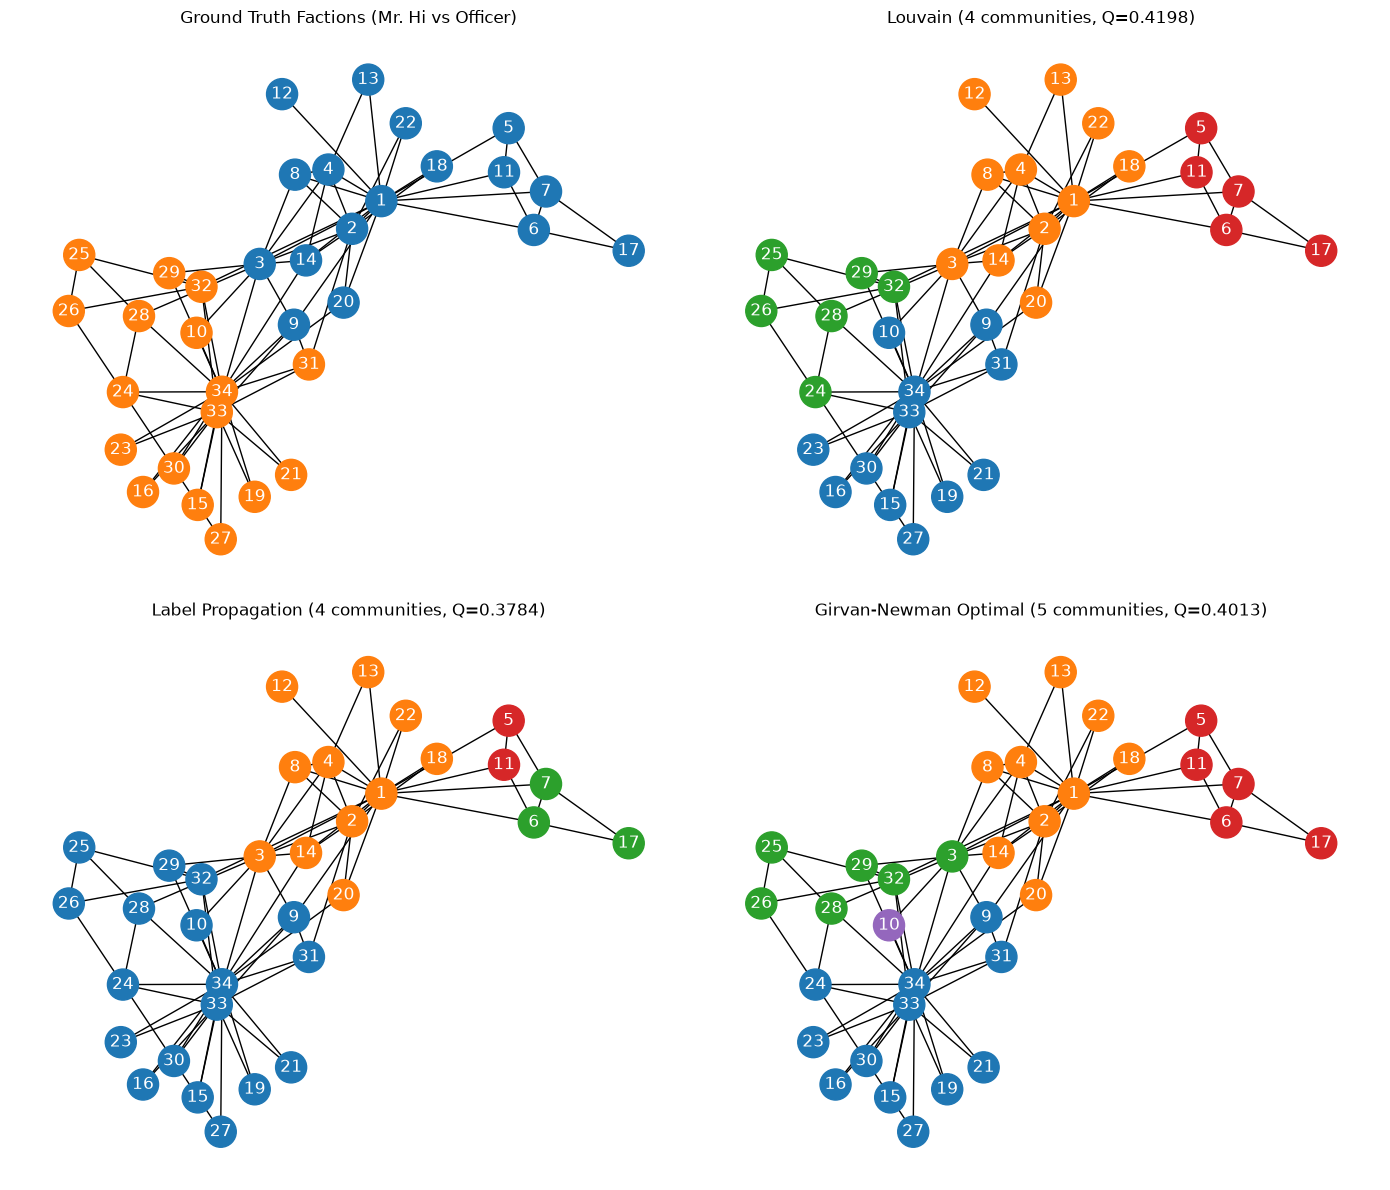

In [6]:
# 4-Panel Community Comparison
palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Ground Truth
c_gt_colors = ["#1f77b4" if ground_truth[n] == "Mr. Hi" else "#ff7f0e" for n in G.nodes()]
nx.draw_networkx(G, pos, node_color=c_gt_colors, with_labels=True, node_size=500, font_color="white", ax=axes[0, 0])
axes[0, 0].set_title("Ground Truth Factions (Mr. Hi vs Officer)")
axes[0, 0].axis("off")

# Louvain
comm_l = {n: i for i, c in enumerate(c_louvain) for n in c}
nx.draw_networkx(G, pos, node_color=[palette[comm_l[n] % len(palette)] for n in G.nodes()], with_labels=True, node_size=500, font_color="white", ax=axes[0, 1])
axes[0, 1].set_title(f"Louvain ({len(c_louvain)} communities, Q={q_louvain:.4f})")
axes[0, 1].axis("off")

# LPA
comm_p = {n: i for i, c in enumerate(c_lpa) for n in c}
nx.draw_networkx(G, pos, node_color=[palette[comm_p[n] % len(palette)] for n in G.nodes()], with_labels=True, node_size=500, font_color="white", ax=axes[1, 0])
axes[1, 0].set_title(f"Label Propagation ({len(c_lpa)} communities, Q={q_lpa:.4f})")
axes[1, 0].axis("off")

# Girvan-Newman Optimal
comm_g = {n: i for i, c in enumerate(best_gn) for n in c}
nx.draw_networkx(G, pos, node_color=[palette[comm_g[n] % len(palette)] for n in G.nodes()], with_labels=True, node_size=500, font_color="white", ax=axes[1, 1])
axes[1, 1].set_title(f"Girvan-Newman Optimal ({len(best_gn)} communities, Q={best_q:.4f})")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

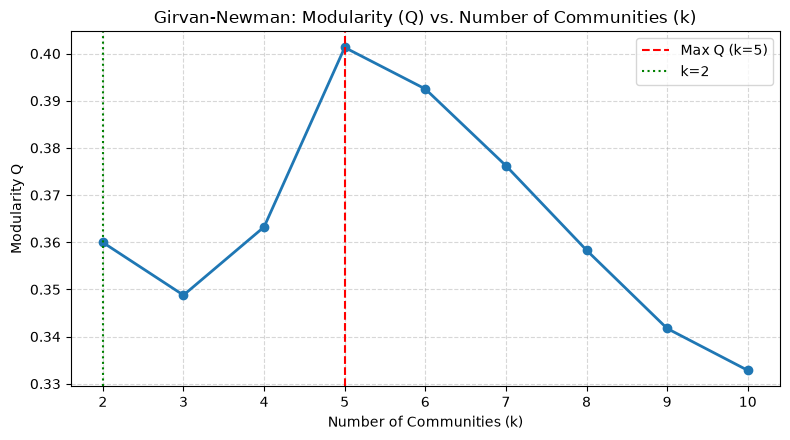

In [7]:
# Girvan-Newman Modularity Curve
k_vals = [h[0] for h in gn_history]
q_vals = [h[1] for h in gn_history]

plt.figure(figsize=(8, 4.5))
plt.plot(k_vals, q_vals, marker="o", color="#1f77b4", linewidth=2)
plt.axvline(x=len(best_gn), color="red", linestyle="--", label=f"Max Q (k={len(best_gn)})")
plt.axvline(x=2, color="green", linestyle=":", label="k=2")
plt.title("Girvan-Newman: Modularity (Q) vs. Number of Communities (k)")
plt.xlabel("Number of Communities (k)")
plt.ylabel("Modularity Q")
plt.xticks(k_vals)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

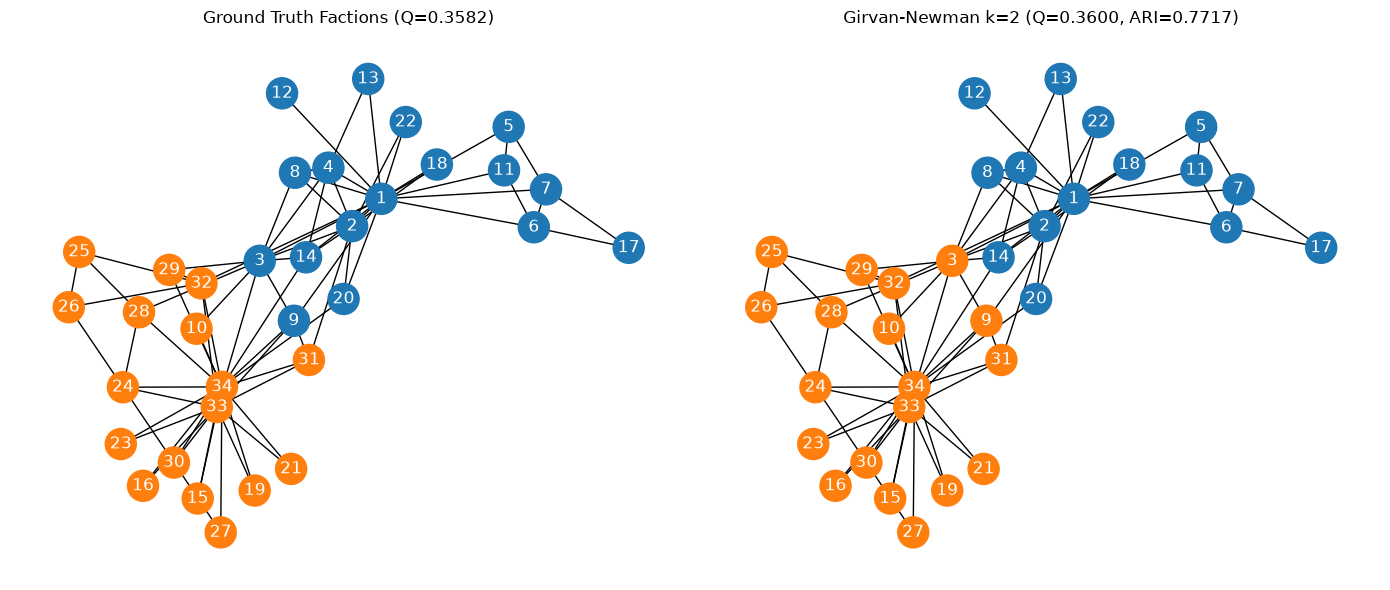

In [8]:
# Ground Truth vs Girvan-Newman k=2
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

nx.draw_networkx(G, pos, node_color=c_gt_colors, with_labels=True, node_size=500, font_color="white", ax=axes[0])
axes[0].set_title(f"Ground Truth Factions (Q={q_gt:.4f})")
axes[0].axis("off")

k2_map = {n: i for i, c in enumerate(gn_k2) for n in c}
cluster_1_idx = k2_map[1]
k2_colors = ["#1f77b4" if k2_map[n] == cluster_1_idx else "#ff7f0e" for n in G.nodes()]

nx.draw_networkx(G, pos, node_color=k2_colors, with_labels=True, node_size=500, font_color="white", ax=axes[1])
axes[1].set_title(f"Girvan-Newman k=2 (Q={q_gn_k2:.4f}, ARI={adjusted_rand_score(y_gt, y_gn_k2):.4f})")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 7. Node Level Analysis

In [9]:
# Comparison of node assignments
node_df = pd.DataFrame({
    "Node": node_list,
    "Degree": [G.degree(n) for n in node_list],
    "Ground_Truth": y_gt,
    "Louvain": y_louvain,
    "LPA": y_lpa,
    "GN_Optimal": y_gn_opt,
    "GN_k2": ["Mr. Hi" if k2_map[n] == cluster_1_idx else "Officer" for n in node_list]
})

# Check node with discrepancy between GN k=2 and Ground Truth
diff = node_df[node_df["Ground_Truth"] != node_df["GN_k2"]]
diff

,Node,Degree,Ground_Truth,Louvain,LPA,GN_Optimal,GN_k2
2,3,10,Mr. Hi,Louvain_2,LPA_2,GN_Opt_3,Officer
8,9,5,Mr. Hi,Louvain_1,LPA_1,GN_Opt_1,Officer
